In [158]:
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import autocorrelation_plot

In [159]:
sales = pd.read_csv('train.csv')
sales.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.00,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.00,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.00,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37


In [160]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [161]:
sales['Order Date'] = pd.to_datetime(sales['Order Date'], format ='%d/%m/%Y')

In [162]:
sales_date = sales.set_index('Order Date')

In [163]:
sales_date.head(3)

,Row ID,Order ID,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
Order Date,,,,,,,,,,,,,,,,,
2017-11-08,1,CA-2017-152156,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
2017-11-08,2,CA-2017-152156,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2017-06-12,3,CA-2017-138688,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.00,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62


In [164]:
sales_date['count'] = 1
sales_days = sales_date.resample('1ME').count()['count']
sales_days.head()

Order Date
2015-01-31     77
2015-02-28     46
2015-03-31    154
2015-04-30    130
2015-05-31    121
Freq: ME, Name: count, dtype: int64

In [165]:
sales_days

Order Date
2015-01-31     77
2015-02-28     46
2015-03-31    154
2015-04-30    130
2015-05-31    121
2015-06-30    131
2015-07-31    142
2015-08-31    146
2015-09-30    267
2015-10-31    159
2015-11-30    306
2015-12-31    274
2016-01-31     57
2016-02-29     64
2016-03-31    128
2016-04-30    159
2016-05-31    143
2016-06-30    129
2016-07-31    136
2016-08-31    158
2016-09-30    285
2016-10-31    164
2016-11-30    321
2016-12-31    311
2017-01-31     89
2017-02-28     83
2017-03-31    161
2017-04-30    168
2017-05-31    221
2017-06-30    196
2017-07-31    196
2017-08-31    175
2017-09-30    349
2017-10-31    192
2017-11-30    366
2017-12-31    338
2018-01-31    143
2018-02-28    104
2018-03-31    237
2018-04-30    200
2018-05-31    240
2018-06-30    235
2018-07-31    223
2018-08-31    214
2018-09-30    453
2018-10-31    294
2018-11-30    456
2018-12-31    459
Freq: ME, Name: count, dtype: int64

<Axes: xlabel='Order Date'>

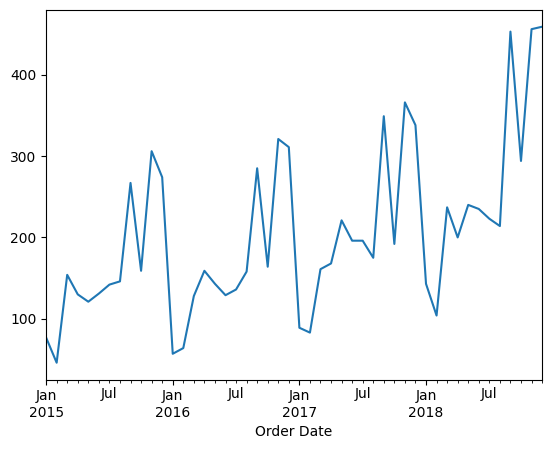

In [166]:
sales_days.plot()

# Task 1:
Run the Augmented Dickey-Fuller test on the sales_days dataset and state whether the series is stationary.

In [167]:
#Adfuller test
from statsmodels.tsa.stattools import adfuller

adfuller(sales_days)

(np.float64(-3.5900533202198917),
 np.float64(0.005954059055898124),
 0,
 47,
 {'1%': np.float64(-3.5778480370438146),
  '5%': np.float64(-2.925338105429433),
  '10%': np.float64(-2.6007735310095064)},
 np.float64(445.13140527612785))

The sales_days can be treated as stationary data

# Task 2: 
Plot the ACF/autocorrelation plot of the raw monthly sales series. Then, apply first-order differencing, plot its ACF plot, and compare how the persistence changes.

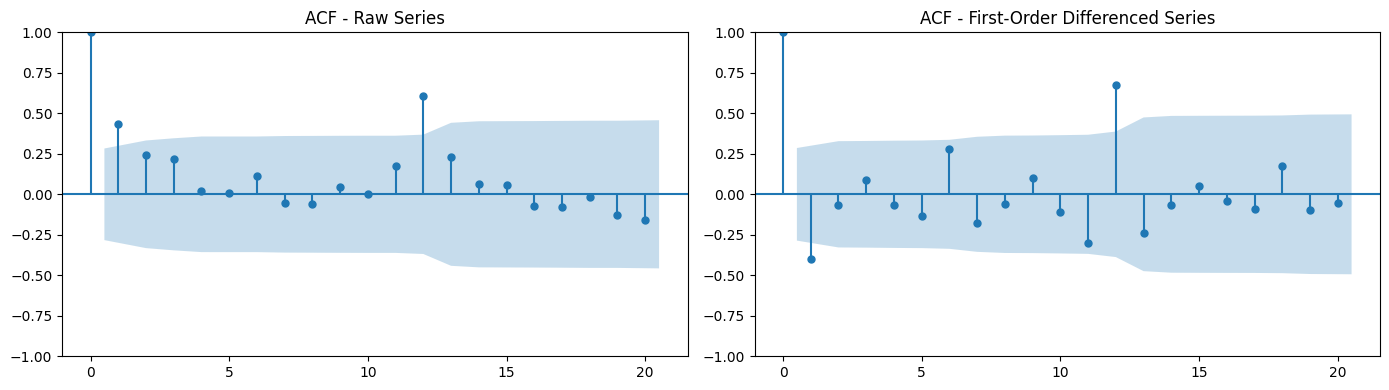

In [168]:
# Plot ACF
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# ACF of the raw monthly series
plot_acf(sales_days, ax=axes[0], lags=20)
axes[0].set_title('ACF - Raw Series')

# ACF of the first-order differenced series
sales_days_diff = sales_days.diff().dropna()
plot_acf(sales_days_diff, ax=axes[1], lags=20)
axes[1].set_title('ACF - First-Order Differenced Series')

plt.tight_layout()
plt.show()

# Task 3

- Set up your results_df tracking table. 
- Fit an initial ARIMA(1,0,1) model on the training set. 
- Generate predictions for the test set.
- Calculate MAE, RMSE, and MAPE, and log the results into your table.

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

from pandas.plotting import autocorrelation_plot

from statsmodels.tsa.arima.model import ARIMA

# Formats floats to display with 2 decimal places and suppresses scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)

results_df = pd.DataFrame(columns=['Model', 'MAE', 'RMSE', 'MAPE'])

def log_experiment(df, model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    
    new_row = pd.DataFrame({'Model': [model_name], 'MAE': [mae], 'RMSE': [rmse], 'MAPE': [mape]})
    return pd.concat([df, new_row], ignore_index=True)

In [170]:
train = sales_days[:"31-12-2017"]
test = sales_days["01-01-2018":]


model = ARIMA(train, order = (1,0,0))
results = model.fit()
results.summary()



<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                  count   No. Observations:                   36
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -209.006
Date:                Wed, 09 Sep 2026   AIC                            424.011
Time:                        10:55:30   BIC                            428.762
Sample:                    01-31-2015   HQIC                           425.669
                         - 12-31-2017                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        181.9093     24.594      7.397      0.000     133.706     230.112
ar.L1          0.3833      0.199      1.925      0.054      -0.007       0.774
sigma2      6439.5879   1841.110      3.498      0.000    2831.079       1e+04
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):                 1.27
Prob(Q):                              0.88   Prob(JB):                         0.53
Heteroskedasticity (H):               1.74   Skew:                             0.45
Prob(H) (two-sided):                  0.35   Kurtosis:                         2.86
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [171]:
def create_forecast(model, start, end):
    forecast = model.get_prediction(start=start, end=end)

    return (
        forecast.predicted_mean,
        forecast.conf_int()
    )

In [172]:
forecast_mean, confidence_intervals = create_forecast(
    results,
    "2018-01-31",
    "2018-12-31"
)

In [173]:
print(confidence_intervals.columns)

Index(['lower count', 'upper count'], dtype='str')


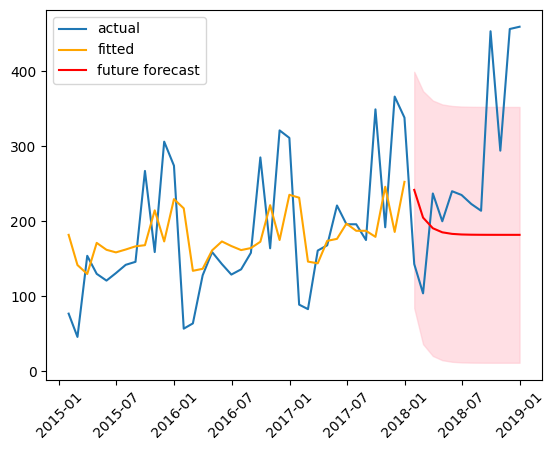

In [174]:
def plot_sales_forecast(
    sales_days,
    fitted_values,
    forecast_mean,
    confidence_intervals
):
    plt.plot(sales_days, label="actual")
    plt.plot(fitted_values, color="orange", label="fitted")
    plt.plot(forecast_mean, color="red", label="future forecast")

    plt.fill_between(
        forecast_mean.index,
        confidence_intervals.iloc[:, 0],
        confidence_intervals.iloc[:, 1],
        color="pink",
        alpha=0.5
    )

    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

plot_sales_forecast(
    sales_days,
    results.fittedvalues,
    forecast_mean,
    confidence_intervals
)

In [175]:
results_df = log_experiment(results_df, "AR_1", test, forecast_mean)
results_df

,Model,MAE,RMSE,MAPE
0,AR_1,114.77,149.70,0.41


In [176]:
model = ARIMA(train, order = (1,0,1))
results = model.fit()
results.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                  count   No. Observations:                   36
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -208.909
Date:                Wed, 09 Sep 2026   AIC                            425.818
Time:                        10:55:31   BIC                            432.152
Sample:                    01-31-2015   HQIC                           428.029
                         - 12-31-2017                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        181.9522     29.689      6.129      0.000     123.764     240.141
ar.L1          0.5754      0.419      1.372      0.170      -0.247       1.397
ma.L1         -0.2124      0.478     -0.444      0.657      -1.149       0.724
sigma2      6386.9940   1755.641      3.638      0.000    2946.001    9827.987
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 0.46
Prob(Q):                              0.97   Prob(JB):                         0.79
Heteroskedasticity (H):               1.83   Skew:                             0.26
Prob(H) (two-sided):                  0.31   Kurtosis:                         2.80
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [177]:
forecast_mean, confidence_intervals = create_forecast(
    results,
    "2018-01-31",
    "2018-12-31"
)

In [178]:
results_df = log_experiment(results_df, "ARMA_1", test, forecast_mean)
results_df

,Model,MAE,RMSE,MAPE
0,AR_1,114.77,149.70,0.41
1,ARMA_1,113.80,150.49,0.42


# Task 4

Inspect the ACF and PACF of the differenced series to decide an appropriate MA(q) and AR (p) order, and log a new ARIMA(p,1,q) model into your results_df. Compare its MAE, RMSE, and MAPE against the baseline.

# Task 5

Because retail sales have strong yearly seasonality, train a seasonal configuration (or use auto_arima) to capture annual cycles. Add the new scores to results_df.

# Task 6

- Add an exogenous variable from the dataset in a SARIMAX model.
- Evalaute and visualise the results.
- Add the new scores to results_df and compare them. 